# Real-data black-box adversarial-cluster study: Forest CoverType

This replication uses the real-world Forest CoverType dataset: cartographic terrain observations labelled by forest cover type. It tests the two most common cover types (classes 1 and 2), using the dataset's ten continuous terrain measurements. The binary indicator columns are intentionally excluded: unconstrained continuous perturbations would make those one-hot features invalid.

The study trains a decision tree, MLP, and an **RBF-kernel SVM**, then attacks a label-only black-box API with HopSkipJump and Boundary Attack. It measures Aidan's corrected adversarial-cluster density after successful attacks. A real-data replication can strengthen or challenge an observed pattern, but it cannot prove that cluster density causes poor model reliability.

In [18]:
from collections.abc import Callable
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from art.attacks.evasion import BoundaryAttack, DecisionTreeAttack, HopSkipJump
from art.estimators.classification import BlackBoxClassifier
from art.estimators.classification.scikitlearn import ScikitlearnDecisionTreeClassifier
from sklearn.cluster import OPTICS
from sklearn.datasets import fetch_covtype
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 41
QUICK_RUN = True
SUBSET_SIZE = 15_000 if QUICK_RUN else 45_000
ATTACK_SAMPLE_SIZE = 50 if QUICK_RUN else 200
BIAS_ATTACK_SAMPLE_SIZE = 30 if QUICK_RUN else 100
CONTINUOUS_FEATURE_COUNT = 10
TARGET_CLASSES = np.array([1, 2])
BIASED_CLASS = 1  # Encoded cover type 2.
CLASS_2_RETENTION_FRACTIONS = (1.0, 0.75, 0.50, 0.25)
OPTICS_MIN_SAMPLES = 5
L2_BUDGET = 0.30
DECISION_TREE_ATTACK_OFFSET = 0.001
PROJECT_ROOT = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "pyproject.toml").is_file()
)
DATA_CACHE = PROJECT_ROOT / "data" / "sklearn_cache"
OUTPUT_DIR = PROJECT_ROOT / "data" / "real_data_cluster_density"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HSJ_PARAMETERS = {
    "max_iter": 8 if QUICK_RUN else 30,
    "max_eval": 250 if QUICK_RUN else 2_000,
    "init_eval": 25 if QUICK_RUN else 100,
    "init_size": 25 if QUICK_RUN else 100,
}
BOUNDARY_PARAMETERS = {
    "max_iter": 15 if QUICK_RUN else 250,
    "num_trial": 5 if QUICK_RUN else 15,
    "sample_size": 8 if QUICK_RUN else 20,
    "init_size": 25 if QUICK_RUN else 100,
}

print(
    f"quick_run={QUICK_RUN}; subset={SUBSET_SIZE}; attack_samples={ATTACK_SAMPLE_SIZE}; "
    f"bias_attack_samples={BIAS_ATTACK_SAMPLE_SIZE}; L2 budget={L2_BUDGET}; "
    f"output={OUTPUT_DIR}"
)

quick_run=True; subset=15000; attack_samples=50; bias_attack_samples=30; L2 budget=0.3; output=c:\Auditingv2\Auditing\data\real_data_cluster_density


## Data protocol and models

`fetch_covtype` obtains 581,012 observations from the UCI Forest CoverType data distributed with scikit-learn. A fixed stratified subset of cover types 1 and 2 is selected, then split into model training and evaluation sets. Min-max scaling is fitted only on model-training data. The normalized `[0, 1]^10` box defines the attack domain.

The perturbation constraint remains a simplification: it respects per-feature observed ranges but not all terrain-variable correlations or physical constraints. Results must therefore be interpreted as robustness within this normalized tabular threat model.

In [19]:
cover_type = fetch_covtype(data_home=DATA_CACHE)
feature_names = np.asarray(cover_type.feature_names[:CONTINUOUS_FEATURE_COUNT])
class_mask = np.isin(cover_type.target, TARGET_CLASSES)
X_candidates = cover_type.data[class_mask, :CONTINUOUS_FEATURE_COUNT].astype(np.float32)
y_candidates = cover_type.target[class_mask]

subset_selector = StratifiedShuffleSplit(
    n_splits=1,
    train_size=SUBSET_SIZE,
    random_state=SEED,
)
subset_indices, _ = next(subset_selector.split(X_candidates, y_candidates))
X_subset = X_candidates[subset_indices]
y_subset = (y_candidates[subset_indices] == TARGET_CLASSES[1]).astype(int)

X_model, X_evaluation, y_model, y_evaluation = train_test_split(
    X_subset,
    y_subset,
    test_size=0.25,
    stratify=y_subset,
    random_state=SEED + 1,
)
scaler = MinMaxScaler(clip=True).fit(X_model)
X_model = scaler.transform(X_model).astype(np.float32)
X_evaluation = scaler.transform(X_evaluation).astype(np.float32)

attack_selector = StratifiedShuffleSplit(
    n_splits=1,
    train_size=ATTACK_SAMPLE_SIZE,
    random_state=SEED + 2,
)
attack_indices, _ = next(attack_selector.split(X_evaluation, y_evaluation))
X_attack = X_evaluation[attack_indices]
y_attack = y_evaluation[attack_indices]

bias_attack_selector = StratifiedShuffleSplit(
    n_splits=1,
    train_size=BIAS_ATTACK_SAMPLE_SIZE,
    random_state=SEED + 3,
)
bias_attack_indices, _ = next(bias_attack_selector.split(X_attack, y_attack))
X_bias_attack = X_attack[bias_attack_indices]
y_bias_attack = y_attack[bias_attack_indices]

def make_models():
    return {
        "decision_tree": DecisionTreeClassifier(
            max_depth=14,
            min_samples_leaf=10,
            random_state=SEED,
        ),
        "mlp": MLPClassifier(
            hidden_layer_sizes=(64, 32),
            alpha=1e-3,
            early_stopping=True,
            max_iter=750,
            random_state=SEED,
        ),
        "rbf_svm": SVC(
            C=2.0,
            kernel="rbf",
            gamma="scale",
            probability=False,
            random_state=SEED,
        ),
    }

models = make_models()
for model in models.values():
    model.fit(X_model, y_model)

pd.DataFrame(
    {
        "dataset": ["Forest CoverType"] * 3,
        "split": ["model training", "evaluation", "attack"],
        "samples": [len(X_model), len(X_evaluation), len(X_attack)],
        "cover_type_1": [(y_model == 0).sum(), (y_evaluation == 0).sum(), (y_attack == 0).sum()],
        "cover_type_2": [(y_model == 1).sum(), (y_evaluation == 1).sum(), (y_attack == 1).sum()],
    }
)

c:\Users\johns\.conda\envs\environment\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,dataset,split,samples,cover_type_1,cover_type_2
0,Forest CoverType,model training,11250,4813,6437
1,Forest CoverType,evaluation,3750,1605,2145
2,Forest CoverType,attack,50,21,29


## Corrected adversarial-cluster density

For each model and attack, retain only outputs `z_i` that changed the model prediction of an initially correct input. OPTICS clusters these successful adversarial outputs in the **original 10-dimensional scaled feature space**; noise points are excluded.

For cluster `C_j` with `n_j` points, the score is:

`cluster_density(C_j) = choose(n_j, 2) / (1 + sum_{a < b} ||z_a - z_b||_2)`.

The reported score is the unweighted mean across non-noise clusters. This is the intended Aidan formula, fixed to sum unique pairwise distances between points. It is an after-attack concentration metric, not a pre-attack predictor or a model reliability score.

In [20]:
def adversarial_cluster_metrics(
    adversarial_points: np.ndarray,
    min_samples: int,
) -> tuple[dict[str, float | int], np.ndarray]:
    total_point_count = len(adversarial_points)
    if total_point_count < min_samples:
        return (
            {
                "adversarial_cluster_density": np.nan,
                "adversarial_cluster_count": 0,
                "clustered_adversarial_points": 0,
                "noise_adversarial_points": total_point_count,
            },
            np.full(total_point_count, -1, dtype=int),
        )

    cluster_labels = OPTICS(min_samples=min_samples).fit_predict(adversarial_points)
    non_noise_labels = np.unique(cluster_labels[cluster_labels != -1])
    cluster_scores = []
    clustered_points = 0

    for label in non_noise_labels:
        points = adversarial_points[cluster_labels == label]
        cluster_size = len(points)
        pair_count = cluster_size * (cluster_size - 1) // 2
        if pair_count == 0:
            continue
        differences = points[:, np.newaxis, :] - points[np.newaxis, :, :]
        pairwise_distances = np.linalg.norm(differences, axis=2)
        total_separation = pairwise_distances[np.triu_indices(cluster_size, k=1)].sum()
        cluster_scores.append(pair_count / (total_separation + 1.0))
        clustered_points += cluster_size

    return (
        {
            "adversarial_cluster_density": float(np.mean(cluster_scores))
            if cluster_scores
            else np.nan,
            "adversarial_cluster_count": len(cluster_scores),
            "clustered_adversarial_points": clustered_points,
            "noise_adversarial_points": total_point_count - clustered_points,
        },
        cluster_labels,
    )

## Label-only black-box attacks and Aidan's white-box tree reference

`CountingLabelOracle` provides ART with only a one-hot encoding of predicted labels. It exposes no gradients, probabilities, parameters, tree structure, support vectors, or training examples. The RBF SVM is therefore attacked as a black box despite having a non-linear kernel.

A deterministic initial point from the attack batch whose oracle label differs is supplied to each attack. This prevents ART from using unseeded random initialization while preserving the label-only black-box boundary. Global NumPy randomness is also reset per model/attack pair for reproducible random-search steps.

For the decision tree only, `run_decision_tree_white_box_attack` also runs Aidan's ART `DecisionTreeAttack` with `offset=0.001`. It receives the trained tree object, follows its decision paths, and moves features across selected tree thresholds. It is therefore a **white-box reference**, not a black-box result. Its outputs are clipped to the same normalized `[0, 1]^10` input domain before measurement.

In [21]:
class CountingLabelOracle:
    def __init__(self, predict: Callable[[np.ndarray], np.ndarray], classes: np.ndarray):
        self._predict = predict
        self._classes = np.asarray(classes)
        self._class_to_index = {label: index for index, label in enumerate(self._classes)}
        self.queries = 0

    def __call__(self, inputs: np.ndarray) -> np.ndarray:
        inputs = np.asarray(inputs)
        self.queries += len(inputs)
        labels = self._predict(inputs)
        indices = np.fromiter(
            (self._class_to_index[label] for label in labels),
            dtype=int,
            count=len(labels),
        )
        return np.eye(len(self._classes), dtype=np.float32)[indices]


def deterministic_adversarial_initialization(
    inputs: np.ndarray,
    base_predictions: np.ndarray,
) -> np.ndarray:
    initial_indices = np.empty(len(inputs), dtype=int)
    for index, prediction in enumerate(base_predictions):
        alternatives = np.flatnonzero(base_predictions != prediction)
        if len(alternatives) == 0:
            raise ValueError(
                "The attack batch needs predictions from at least two classes "
                "to provide a deterministic adversarial initialization."
            )
        initial_indices[index] = alternatives[0]
    return inputs[initial_indices].copy()


def run_black_box_attack(
    model_name: str,
    model,
    attack_name: str,
    attack_seed: int,
    inputs: np.ndarray,
    labels: np.ndarray,
) -> pd.DataFrame:
    oracle = CountingLabelOracle(model.predict, model.classes_)
    black_box = BlackBoxClassifier(
        predict_fn=oracle,
        input_shape=(inputs.shape[1],),
        nb_classes=len(model.classes_),
        clip_values=(0.0, 1.0),
    )
    if attack_name == "hopskipjump":
        attack = HopSkipJump(
            classifier=black_box,
            targeted=False,
            norm=2,
            batch_size=32,
            verbose=False,
            **HSJ_PARAMETERS,
        )
    elif attack_name == "boundary":
        attack = BoundaryAttack(
            estimator=black_box,
            targeted=False,
            batch_size=32,
            verbose=False,
            **BOUNDARY_PARAMETERS,
        )
    else:
        raise ValueError(f"Unsupported attack: {attack_name}")

    base_predictions = oracle(inputs).argmax(axis=1)
    x_adv_init = deterministic_adversarial_initialization(inputs, base_predictions)
    np.random.seed(attack_seed)
    adversarial = attack.generate(inputs.astype(np.float32), x_adv_init=x_adv_init)
    adversarial_predictions = oracle(adversarial).argmax(axis=1)
    perturbations = adversarial - inputs
    l2_distance = np.linalg.norm(perturbations, axis=1)
    linf_distance = np.max(np.abs(perturbations), axis=1)
    clean_correct = base_predictions == labels
    changed_label = adversarial_predictions != base_predictions
    attack_success = clean_correct & changed_label
    attack_success_at_budget = attack_success & (l2_distance <= L2_BUDGET)

    return pd.DataFrame(
        {
            "model": model_name,
            "attack": attack_name,
            "access_mode": "label_only_black_box",
            "sample_index": np.arange(len(inputs)),
            "true_label": labels,
            "base_prediction": base_predictions,
            "adversarial_prediction": adversarial_predictions,
            "clean_correct": clean_correct,
            "changed_label": changed_label,
            "attack_success": attack_success,
            "attack_success_at_budget": attack_success_at_budget,
            "l2_distance": l2_distance,
            "linf_distance": linf_distance,
            "black_box_queries": oracle.queries,
            **{
                f"x{feature_index}": inputs[:, feature_index]
                for feature_index in range(inputs.shape[1])
            },
            **{
                f"adv_x{feature_index}": adversarial[:, feature_index]
                for feature_index in range(inputs.shape[1])
            },
        }
    )


def run_decision_tree_white_box_attack(
    model: DecisionTreeClassifier,
    inputs: np.ndarray,
    labels: np.ndarray,
) -> pd.DataFrame:
    classifier = ScikitlearnDecisionTreeClassifier(
        model=model,
        clip_values=(0.0, 1.0),
    )
    attack = DecisionTreeAttack(
        classifier=classifier,
        offset=DECISION_TREE_ATTACK_OFFSET,
        verbose=False,
    )
    base_predictions = model.predict(inputs)
    adversarial = np.clip(
        attack.generate(inputs.astype(np.float32)),
        0.0,
        1.0,
    ).astype(np.float32)
    adversarial_predictions = model.predict(adversarial)
    perturbations = adversarial - inputs
    l2_distance = np.linalg.norm(perturbations, axis=1)
    linf_distance = np.max(np.abs(perturbations), axis=1)
    clean_correct = base_predictions == labels
    changed_label = adversarial_predictions != base_predictions
    attack_success = clean_correct & changed_label
    attack_success_at_budget = attack_success & (l2_distance <= L2_BUDGET)

    return pd.DataFrame(
        {
            "model": "decision_tree",
            "attack": "decision_tree_white_box",
            "access_mode": "white_box_tree_paths",
            "sample_index": np.arange(len(inputs)),
            "true_label": labels,
            "base_prediction": base_predictions,
            "adversarial_prediction": adversarial_predictions,
            "clean_correct": clean_correct,
            "changed_label": changed_label,
            "attack_success": attack_success,
            "attack_success_at_budget": attack_success_at_budget,
            "l2_distance": l2_distance,
            "linf_distance": linf_distance,
            "black_box_queries": 0,
            **{
                f"x{feature_index}": inputs[:, feature_index]
                for feature_index in range(inputs.shape[1])
            },
            **{
                f"adv_x{feature_index}": adversarial[:, feature_index]
                for feature_index in range(inputs.shape[1])
            },
        }
    )


clean_accuracy = {
    model_name: accuracy_score(y_evaluation, model.predict(X_evaluation))
    for model_name, model in models.items()
}
attack_results = pd.concat(
    [
        *[
            run_black_box_attack(
            model_name,
            model,
            attack_name,
            SEED + 100 * model_index + attack_index,
            X_attack,
            y_attack,
            )
            for model_index, (model_name, model) in enumerate(models.items())
            for attack_index, attack_name in enumerate(("hopskipjump", "boundary"))
        ],
        run_decision_tree_white_box_attack(models["decision_tree"], X_attack, y_attack),
    ],
    ignore_index=True,
)

## Reliability and cluster summaries

Empirical robust accuracy is `1 - mean(attack_success_at_budget)` over every attack input; an initially incorrect input is therefore non-robust under this convention. The conservative reliability score is the lowest empirical robust accuracy across attacks.

The conservative reliability score uses only label-only black-box attacks. The Aidan white-box tree reference is reported in the same attack and cluster tables, but excluded from this black-box score. Cluster density describes the geometry of failures found by an attack. It must be read together with the successful point count, cluster count, clustered point count, noise count, and access mode; it does not establish causation or predict a failure before the attack.

In [22]:
def summarise_attack(group: pd.DataFrame) -> pd.Series:
    eligible = group["clean_correct"]
    successful_distances = group.loc[eligible & group["attack_success"], "l2_distance"]
    return pd.Series(
        {
            "clean_accuracy": clean_accuracy[group.name[0]],
            "attack_inputs": len(group),
            "initially_correct": int(eligible.sum()),
            "conditional_attack_success_rate": group.loc[eligible, "attack_success"].mean(),
            "empirical_robust_accuracy_at_l2_budget": 1.0
            - group["attack_success_at_budget"].mean(),
            "median_successful_boundary_l2": successful_distances.median(),
            "label_oracle_queries_per_attack_input": (
                group["black_box_queries"].iloc[0] / len(group)
                if group.name[2] == "label_only_black_box"
                else np.nan
            ),
        }
    )


attack_summary = (
    attack_results.groupby(["model", "attack", "access_mode"], sort=False)
    .apply(summarise_attack, include_groups=False)
    .reset_index()
)
cluster_rows = []
cluster_assignments = []
adversarial_columns = [f"adv_x{index}" for index in range(CONTINUOUS_FEATURE_COUNT)]
attack_group_columns = ["model", "attack", "access_mode"]
for group_key, group in attack_results.groupby(attack_group_columns, sort=False):
    successful = group.loc[group["clean_correct"] & group["attack_success"]].copy()
    metrics, cluster_labels = adversarial_cluster_metrics(
        successful[adversarial_columns].to_numpy(),
        OPTICS_MIN_SAMPLES,
    )
    metrics.update(dict(zip(attack_group_columns, group_key)))
    metrics["successful_adversarial_points"] = len(successful)
    cluster_rows.append(metrics)
    successful["adversarial_cluster_label"] = cluster_labels
    cluster_assignments.append(
        successful[attack_group_columns + ["sample_index", "adversarial_cluster_label"]]
    )

cluster_summary = pd.DataFrame(cluster_rows)
cluster_assignments = pd.concat(cluster_assignments, ignore_index=True)
attack_results = attack_results.merge(
    cluster_assignments,
    how="left",
    on=attack_group_columns + ["sample_index"],
)
reliability_summary = (
    attack_summary.loc[
        attack_summary["access_mode"] == "label_only_black_box"
    ].groupby("model", as_index=False)
    .agg(
        clean_accuracy=("clean_accuracy", "first"),
        empirical_reliability_at_l2_budget=("empirical_robust_accuracy_at_l2_budget", "min"),
        worst_conditional_attack_success_rate=("conditional_attack_success_rate", "max"),
    )
    .sort_values("empirical_reliability_at_l2_budget")
)

attack_results.to_csv(OUTPUT_DIR / "per_sample_outcomes.csv", index=False)
attack_summary.to_csv(OUTPUT_DIR / "attack_summary.csv", index=False)
cluster_summary.to_csv(OUTPUT_DIR / "adversarial_cluster_summary.csv", index=False)
reliability_summary.to_csv(OUTPUT_DIR / "reliability_summary.csv", index=False)

display(reliability_summary.round(3))
display(attack_summary.merge(cluster_summary, on=attack_group_columns).round(3))

,model,clean_accuracy,empirical_reliability_at_l2_budget,worst_conditional_attack_success_rate
0,decision_tree,0.780,0.22,1.0
2,rbf_svm,0.785,0.30,1.0
1,mlp,0.775,0.32,1.0


,model,attack,access_mode,clean_accuracy,attack_inputs,initially_correct,conditional_attack_success_rate,empirical_robust_accuracy_at_l2_budget,median_successful_boundary_l2,label_oracle_queries_per_attack_input,adversarial_cluster_density,adversarial_cluster_count,clustered_adversarial_points,noise_adversarial_points,successful_adversarial_points
0,decision_tree,hopskipjump,label_only_black_box,0.780,50.0,41.0,1.0,0.22,0.082,493.36,2.258,2,21,20,41
1,decision_tree,boundary,label_only_black_box,0.780,50.0,41.0,1.0,0.26,0.073,230.58,2.323,2,20,21,41
2,mlp,hopskipjump,label_only_black_box,0.775,50.0,38.0,1.0,0.32,0.113,492.00,1.909,1,20,18,38
3,mlp,boundary,label_only_black_box,0.775,50.0,38.0,1.0,0.32,0.104,236.48,2.329,1,6,32,38
4,rbf_svm,hopskipjump,label_only_black_box,0.785,50.0,39.0,1.0,0.30,0.102,492.00,1.416,1,39,0,39
5,rbf_svm,boundary,label_only_black_box,0.785,50.0,39.0,1.0,0.32,0.099,233.04,2.192,3,18,21,39
6,decision_tree,decision_tree_white_box,white_box_tree_paths,0.780,50.0,41.0,1.0,0.56,0.297,NaN,2.350,2,18,23,41


## Controlled representation-bias sweep

This sweep creates a controlled **training representation bias**: all cover type 1 training examples remain, while the retained share of cover type 2 is 100%, 75%, 50%, or 25%. The scaler, evaluation set, and attack inputs are fixed across every level, so the horizontal axis is the deliberate change in class-2 representation rather than a change in test data or perturbation scale.

This is not a demographic-fairness measurement: CoverType labels forest type, not a protected characteristic. It tests whether deliberately under-representing one outcome class is associated with a trend in the geometry and rate of found black-box failures. The plot shows every model/attack combination instead of averaging away disagreement.

In [23]:
biased_class_indices = np.flatnonzero(y_model == BIASED_CLASS)
unbiased_class_indices = np.flatnonzero(y_model != BIASED_CLASS)
biased_class_order = np.random.default_rng(SEED + 4).permutation(biased_class_indices)


def training_with_class_2_underrepresentation(
    class_2_retention_fraction: float,
) -> tuple[np.ndarray, np.ndarray]:
    if not 0.0 < class_2_retention_fraction <= 1.0:
        raise ValueError("class_2_retention_fraction must be in (0, 1].")
    retained_count = max(
        1,
        int(np.floor(len(biased_class_order) * class_2_retention_fraction)),
    )
    selected_indices = np.concatenate(
        [unbiased_class_indices, biased_class_order[:retained_count]]
    )
    return X_model[selected_indices], y_model[selected_indices]


def summarise_bias_attack(group: pd.DataFrame) -> pd.Series:
    eligible = group["clean_correct"]
    successful_distances = group.loc[eligible & group["attack_success"], "l2_distance"]
    return pd.Series(
        {
            "clean_accuracy": group["model_clean_accuracy"].iloc[0],
            "training_samples": group["training_samples"].iloc[0],
            "training_class_2_share": group["training_class_2_share"].iloc[0],
            "attack_inputs": len(group),
            "initially_correct": int(eligible.sum()),
            "conditional_attack_success_rate": group.loc[eligible, "attack_success"].mean(),
            "empirical_robust_accuracy_at_l2_budget": 1.0
            - group["attack_success_at_budget"].mean(),
            "median_successful_boundary_l2": successful_distances.median(),
            "label_oracle_queries_per_attack_input": (
                group["black_box_queries"].iloc[0] / len(group)
                if group.name[4] == "label_only_black_box"
                else np.nan
            ),
        }
    )


bias_result_parts = []
for retention_index, class_2_retention_fraction in enumerate(CLASS_2_RETENTION_FRACTIONS):
    X_biased_model, y_biased_model = training_with_class_2_underrepresentation(
        class_2_retention_fraction
    )
    for model_index, (model_name, model) in enumerate(make_models().items()):
        model.fit(X_biased_model, y_biased_model)
        model_clean_accuracy = accuracy_score(y_evaluation, model.predict(X_evaluation))
        for attack_index, attack_name in enumerate(("hopskipjump", "boundary")):
            result = run_black_box_attack(
                model_name,
                model,
                attack_name,
                SEED + 10_000 + 100 * retention_index + 10 * model_index + attack_index,
                X_bias_attack,
                y_bias_attack,
            )
            result["class_2_retention_fraction"] = class_2_retention_fraction
            result["underrepresentation_percent"] = 100.0 * (1.0 - class_2_retention_fraction)
            result["training_samples"] = len(y_biased_model)
            result["training_class_2_share"] = y_biased_model.mean()
            result["model_clean_accuracy"] = model_clean_accuracy
            bias_result_parts.append(result)
        if model_name == "decision_tree":
            result = run_decision_tree_white_box_attack(
                model,
                X_bias_attack,
                y_bias_attack,
            )
            result["class_2_retention_fraction"] = class_2_retention_fraction
            result["underrepresentation_percent"] = 100.0 * (1.0 - class_2_retention_fraction)
            result["training_samples"] = len(y_biased_model)
            result["training_class_2_share"] = y_biased_model.mean()
            result["model_clean_accuracy"] = model_clean_accuracy
            bias_result_parts.append(result)

bias_attack_results = pd.concat(bias_result_parts, ignore_index=True)
bias_group_columns = [
    "class_2_retention_fraction",
    "underrepresentation_percent",
    "model",
    "attack",
    "access_mode",
]
bias_attack_summary = (
    bias_attack_results.groupby(bias_group_columns, sort=False)
    .apply(summarise_bias_attack, include_groups=False)
    .reset_index()
)

bias_cluster_rows = []
bias_cluster_assignments = []
for group_key, group in bias_attack_results.groupby(bias_group_columns, sort=False):
    successful = group.loc[group["clean_correct"] & group["attack_success"]].copy()
    metrics, cluster_labels = adversarial_cluster_metrics(
        successful[adversarial_columns].to_numpy(),
        OPTICS_MIN_SAMPLES,
    )
    metrics.update(dict(zip(bias_group_columns, group_key)))
    metrics["successful_adversarial_points"] = len(successful)
    bias_cluster_rows.append(metrics)
    successful["adversarial_cluster_label"] = cluster_labels
    bias_cluster_assignments.append(
        successful[bias_group_columns + ["sample_index", "adversarial_cluster_label"]]
    )

bias_cluster_summary = pd.DataFrame(bias_cluster_rows)
bias_cluster_assignments = pd.concat(bias_cluster_assignments, ignore_index=True)
bias_attack_results = bias_attack_results.merge(
    bias_cluster_assignments,
    how="left",
    on=bias_group_columns + ["sample_index"],
)
bias_trend_summary = bias_attack_summary.merge(
    bias_cluster_summary,
    on=bias_group_columns,
)
bias_reliability_summary = (
    bias_attack_summary.loc[
        bias_attack_summary["access_mode"] == "label_only_black_box"
    ].groupby(["class_2_retention_fraction", "underrepresentation_percent", "model"], as_index=False)
    .agg(
        clean_accuracy=("clean_accuracy", "first"),
        training_samples=("training_samples", "first"),
        training_class_2_share=("training_class_2_share", "first"),
        empirical_reliability_at_l2_budget=("empirical_robust_accuracy_at_l2_budget", "min"),
    )
)

bias_attack_results.to_csv(OUTPUT_DIR / "bias_attack_outcomes.csv", index=False)
bias_trend_summary.to_csv(OUTPUT_DIR / "bias_trend_summary.csv", index=False)
bias_reliability_summary.to_csv(OUTPUT_DIR / "bias_reliability_summary.csv", index=False)

display(bias_trend_summary.round(3))

c:\Users\johns\.conda\envs\environment\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\johns\.conda\envs\environment\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\johns\.conda\envs\environment\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\johns\.conda\envs\environment\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was dep

,class_2_retention_fraction,underrepresentation_percent,model,attack,access_mode,clean_accuracy,training_samples,training_class_2_share,attack_inputs,initially_correct,conditional_attack_success_rate,empirical_robust_accuracy_at_l2_budget,median_successful_boundary_l2,label_oracle_queries_per_attack_input,adversarial_cluster_density,adversarial_cluster_count,clustered_adversarial_points,noise_adversarial_points,successful_adversarial_points
0,1.00,0.0,decision_tree,hopskipjump,label_only_black_box,0.780,11250.0,0.572,30.0,22.0,1.0,0.267,0.032,492.533,1.993,2,16,6,22
1,1.00,0.0,decision_tree,boundary,label_only_black_box,0.780,11250.0,0.572,30.0,22.0,1.0,0.300,0.035,232.167,1.931,2,18,4,22
2,1.00,0.0,decision_tree,decision_tree_white_box,white_box_tree_paths,0.780,11250.0,0.572,30.0,22.0,1.0,0.667,0.312,NaN,2.103,1,8,14,22
3,1.00,0.0,mlp,hopskipjump,label_only_black_box,0.773,11250.0,0.572,30.0,20.0,1.0,0.367,0.095,492.000,1.945,2,13,7,20
4,1.00,0.0,mlp,boundary,label_only_black_box,0.773,11250.0,0.572,30.0,20.0,1.0,0.400,0.095,237.500,2.165,1,6,14,20
5,1.00,0.0,rbf_svm,hopskipjump,label_only_black_box,0.785,11250.0,0.572,30.0,21.0,1.0,0.333,0.084,492.000,1.894,2,14,7,21
6,1.00,0.0,rbf_svm,boundary,label_only_black_box,0.785,11250.0,0.572,30.0,21.0,1.0,0.300,0.093,231.633,1.854,2,16,5,21
7,0.75,25.0,decision_tree,hopskipjump,label_only_black_box,0.760,9640.0,0.501,30.0,21.0,1.0,0.300,0.068,492.733,2.124,2,17,4,21
8,0.75,25.0,decision_tree,boundary,label_only_black_box,0.760,9640.0,0.501,30.0,21.0,1.0,0.367,0.082,231.633,2.261,2,16,5,21
9,0.75,25.0,decision_tree,decision_tree_white_box,white_box_tree_paths,0.760,9640.0,0.501,30.0,21.0,1.0,0.633,0.299,NaN,1.322,1,21,0,21


## Visual diagnostics and bias trend

The cluster calculation stays in all ten scaled terrain dimensions. PCA below is only a two-dimensional visualization of those outputs; do not calculate or interpret the reported density from this projection.

The final trend plot uses increasing under-representation of cover type 2 on the horizontal axis. It plots all model/attack combinations separately. Read density only alongside the robust-accuracy panel and the saved success, cluster, and noise counts; the plot does not establish a monotonic or causal relationship.

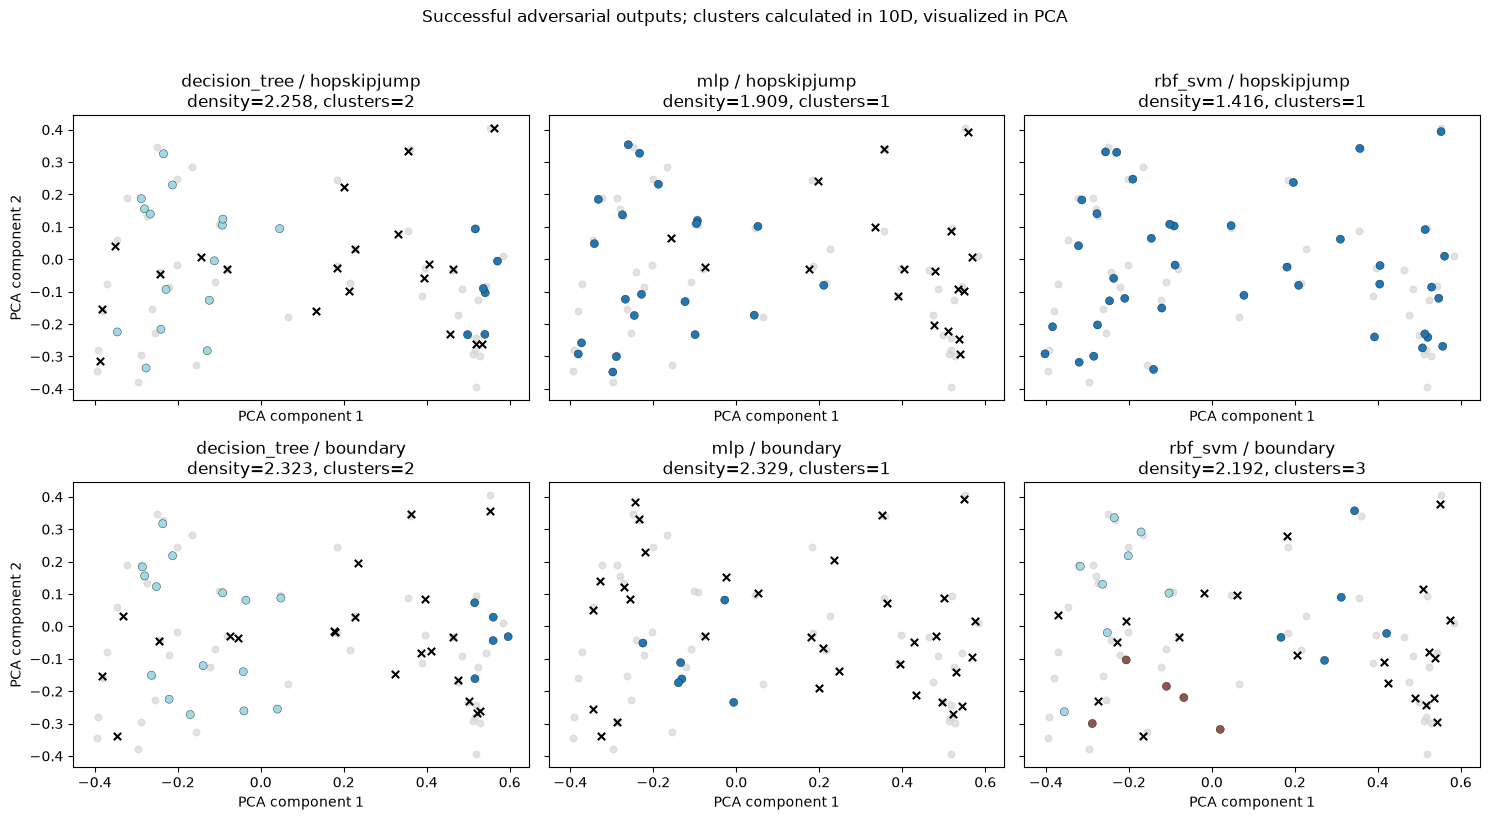

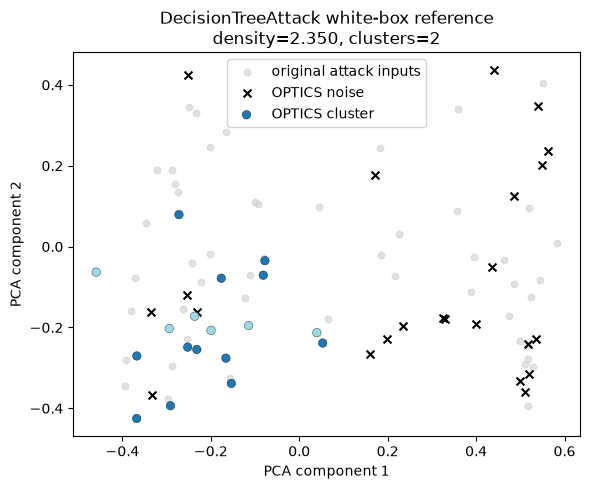

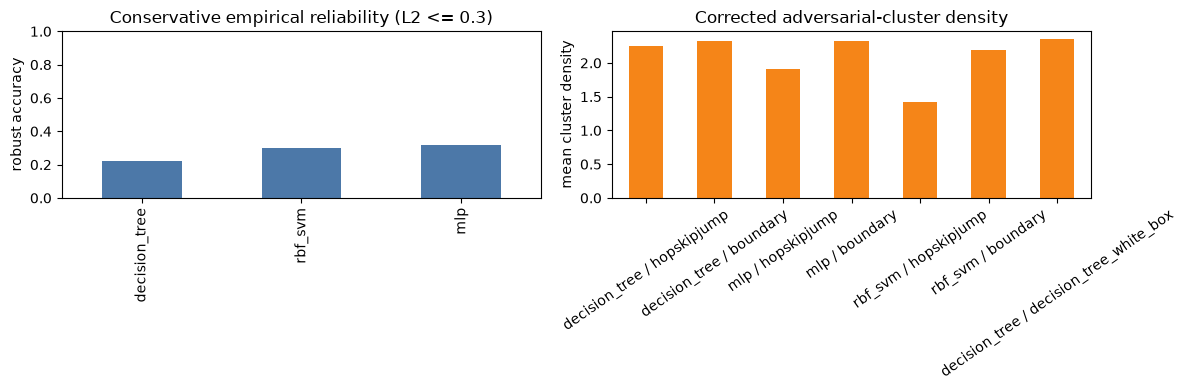

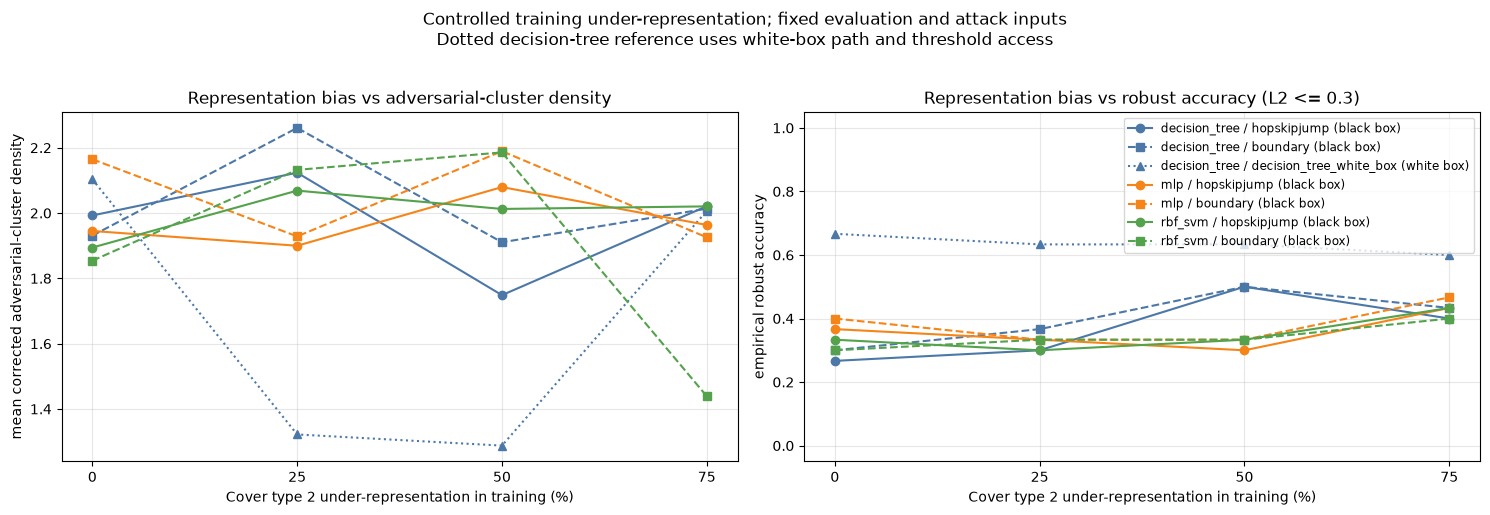

In [24]:
pca = PCA(n_components=2, random_state=SEED).fit(X_model)
baseline_projection = pca.transform(X_attack)

fig, axes = plt.subplots(2, len(models), figsize=(15, 8), sharex=True, sharey=True)
for row, attack_name in enumerate(("hopskipjump", "boundary")):
    for column, model_name in enumerate(models):
        axis = axes[row, column]
        axis.scatter(
            baseline_projection[:, 0],
            baseline_projection[:, 1],
            c="lightgrey",
            s=22,
            alpha=0.65,
            label="original attack inputs",
        )
        subset = attack_results.loc[
            (attack_results["model"] == model_name)
            & (attack_results["attack"] == attack_name)
            & attack_results["clean_correct"]
            & attack_results["attack_success"]
        ].copy()
        adversarial_points = subset[adversarial_columns].to_numpy()
        projection = pca.transform(adversarial_points)
        noise = subset["adversarial_cluster_label"] == -1
        if noise.any():
            axis.scatter(
                projection[noise, 0],
                projection[noise, 1],
                c="black",
                marker="x",
                s=28,
                label="OPTICS noise",
            )
        if (~noise).any():
            axis.scatter(
                projection[~noise, 0],
                projection[~noise, 1],
                c=subset.loc[~noise, "adversarial_cluster_label"],
                cmap="tab20",
                edgecolor="black",
                linewidth=0.25,
                s=34,
                label="OPTICS cluster",
            )
        summary = cluster_summary.loc[
            (cluster_summary["model"] == model_name)
            & (cluster_summary["attack"] == attack_name)
        ].iloc[0]
        density = summary["adversarial_cluster_density"]
        density_text = f"{density:.3f}" if pd.notna(density) else "n/a"
        axis.set_title(
            f"{model_name} / {attack_name}\n"
            f"density={density_text}, clusters={int(summary['adversarial_cluster_count'])}"
        )
        axis.set_xlabel("PCA component 1")
        if column == 0:
            axis.set_ylabel("PCA component 2")
fig.suptitle("Successful adversarial outputs; clusters calculated in 10D, visualized in PCA", y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "adversarial_clusters_pca.png", dpi=160, bbox_inches="tight")
plt.show()

white_box_subset = attack_results.loc[
    (attack_results["model"] == "decision_tree")
    & (attack_results["attack"] == "decision_tree_white_box")
    & attack_results["clean_correct"]
    & attack_results["attack_success"]
].copy()
white_box_projection = pca.transform(white_box_subset[adversarial_columns].to_numpy())
white_box_noise = white_box_subset["adversarial_cluster_label"] == -1
white_box_summary = cluster_summary.loc[
    (cluster_summary["model"] == "decision_tree")
    & (cluster_summary["attack"] == "decision_tree_white_box")
].iloc[0]
fig, axis = plt.subplots(figsize=(6, 5))
axis.scatter(
    baseline_projection[:, 0],
    baseline_projection[:, 1],
    c="lightgrey",
    s=22,
    alpha=0.65,
    label="original attack inputs",
)
if white_box_noise.any():
    axis.scatter(
        white_box_projection[white_box_noise, 0],
        white_box_projection[white_box_noise, 1],
        c="black",
        marker="x",
        s=32,
        label="OPTICS noise",
    )
if (~white_box_noise).any():
    axis.scatter(
        white_box_projection[~white_box_noise, 0],
        white_box_projection[~white_box_noise, 1],
        c=white_box_subset.loc[~white_box_noise, "adversarial_cluster_label"],
        cmap="tab20",
        edgecolor="black",
        linewidth=0.25,
        s=38,
        label="OPTICS cluster",
    )
white_box_density = white_box_summary["adversarial_cluster_density"]
axis.set(
    title=(
        "DecisionTreeAttack white-box reference\n"
        f"density={white_box_density:.3f}, clusters={int(white_box_summary['adversarial_cluster_count'])}"
    ),
    xlabel="PCA component 1",
    ylabel="PCA component 2",
)
axis.legend(loc="best")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "decision_tree_white_box_clusters_pca.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
reliability_summary.plot.bar(
    x="model",
    y="empirical_reliability_at_l2_budget",
    ax=axes[0],
    legend=False,
    ylim=(0, 1),
    color="#4C78A8",
)
axes[0].set(title=f"Conservative empirical reliability (L2 <= {L2_BUDGET})", xlabel="", ylabel="robust accuracy")
cluster_summary.assign(pair=cluster_summary["model"] + " / " + cluster_summary["attack"]).plot.bar(
    x="pair",
    y="adversarial_cluster_density",
    ax=axes[1],
    legend=False,
    color="#F58518",
)
axes[1].set(title="Corrected adversarial-cluster density", xlabel="", ylabel="mean cluster density")
axes[1].tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "reliability_and_cluster_density.png", dpi=160, bbox_inches="tight")
plt.show()

model_colours = {
    "decision_tree": "#4C78A8",
    "mlp": "#F58518",
    "rbf_svm": "#54A24B",
}
attack_styles = {
    "hopskipjump": "-o",
    "boundary": "--s",
    "decision_tree_white_box": ":^",
}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for model_name in models:
    for attack_name, style in attack_styles.items():
        trend = bias_trend_summary.loc[
            (bias_trend_summary["model"] == model_name)
            & (bias_trend_summary["attack"] == attack_name)
        ].sort_values("underrepresentation_percent")
        if trend.empty:
            continue
        access_label = (
            "white box" if trend["access_mode"].iloc[0] == "white_box_tree_paths" else "black box"
        )
        label = f"{model_name} / {attack_name} ({access_label})"
        axes[0].plot(
            trend["underrepresentation_percent"],
            trend["adversarial_cluster_density"],
            style,
            color=model_colours[model_name],
            label=label,
        )
        axes[1].plot(
            trend["underrepresentation_percent"],
            trend["empirical_robust_accuracy_at_l2_budget"],
            style,
            color=model_colours[model_name],
            label=label,
        )

for axis in axes:
    axis.set(
        xlabel="Cover type 2 under-representation in training (%)",
        xticks=[0, 25, 50, 75],
    )
    axis.grid(alpha=0.3)
axes[0].set(
    title="Representation bias vs adversarial-cluster density",
    ylabel="mean corrected adversarial-cluster density",
)
axes[1].set(
    title=f"Representation bias vs robust accuracy (L2 <= {L2_BUDGET})",
    ylabel="empirical robust accuracy",
    ylim=(-0.05, 1.05),
)
axes[1].legend(loc="best", fontsize="small")
fig.suptitle(
    "Controlled training under-representation; fixed evaluation and attack inputs\n"
    "Dotted decision-tree reference uses white-box path and threshold access",
    y=1.02,
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "bias_vs_density_trend.png", dpi=160, bbox_inches="tight")
plt.show()

## Interpretation checklist

- A lower empirical reliability score means a configured black-box attack found more label changes within the selected L2 budget. It does not prove the model is unsafe in every use case.
- Higher adversarial-cluster density means discovered failures are more concentrated. It may help an auditor locate recurring failure modes, but it does not cause or predict attack success.
- `decision_tree_white_box` is Aidan's white-box tree-path attack. It has access to the trained tree and is excluded from the black-box reliability score. It finds a threshold-crossing path, not necessarily the globally smallest L2 perturbation, so compare it with black-box results only as a separate reference.
- Compare density values only under the same scaling, feature set, clustering configuration, and attack budgets. Do not compare the 10D values here directly to the 2D synthetic experiment.
- The bias sweep under-represents only cover type 2 in training. It intentionally changes both class balance and available training sample count, so it is a controlled stress test of representation, not an isolated causal estimate of class balance.
- A stronger follow-up is to repeat this notebook over multiple independent subset and attack seeds, add confidence intervals to the bias trend, and test a second real continuous-feature dataset before making a general claim.